# CM → tracks: review (run 79513, 2026-10-24)

**Aim.** A new set of corrections that makes tracks and K0s *better*, not worse as all earlier attempts did. Trust CDB + K0s as the baseline
(it is not terrible), and treat any CM-vs-CDB difference as suspect until tracks confirm it.

**What this notebook contains** (only what carries information; the many configurations that changed nothing are in `CM_tracks_findings_79513`):
1. Truth from the no-field run, the cluster-position DNL, what the field-off terms are.
2. Space charge from low vs high luminosity inside one fill; static.
3. What the CM predicts for tracks, and how it compares with tracks (CDB, final, α 1.25).
4. K0s from the PR_full sample: width vs φ / η, energy loss.
5. CM-based maps on top of CDB in TpcHadronReco (the only test where tracks improved).
6. **Audit:** errors found in our own analysis today, and the remaining places where we can fool ourselves.
7. Plan.

In [1]:
%matplotlib inline
import sys, os
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display
import cmpos as cm, cmtrk as ct, trkana as ta, review as rv
plt.rcParams['figure.dpi'] = 55
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')

Welcome to JupyROOT 6.30/06


# 1. Truth from the no-field run, DNL, and what the field-off terms are
**Cluster position.** The differential non-linearity (DNL / S-curve) of the module centroid is 150–400 µm peak-to-peak; the 3-pad centre of
gravity on the raw pad sums is 50–100 µm. Correcting the S-curve is what makes the stripe positions usable at the 100 µm level.

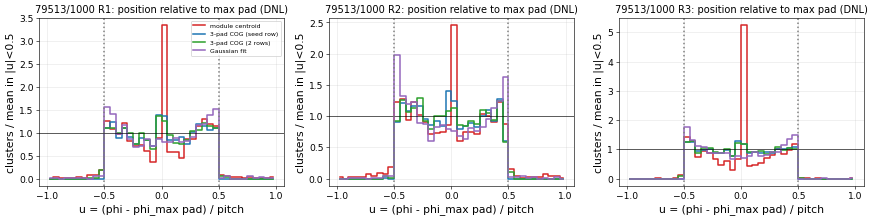

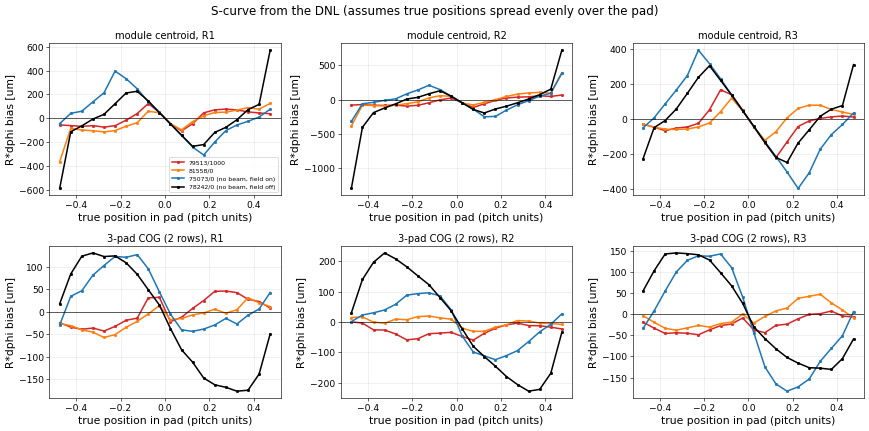

In [2]:
show(cm.fig_dnl(('79513', 1000)), cm.fig_scurve())

**Field-off (78242, no beam, no field) against the rigidly aligned truth** — what the full alignment subtracts:
* a rigid rotation (South −2.05 mrad, North −2.90 mrad) and a translation below 0.6 mm: 1–1.5 mm at R = 50 cm;
* ring means after that: zero (±0.05 mm);
* 36 module offsets per side: South mostly ±0.3 mm, North up to ±0.7 mm (each known to ≈0.12 mm, so real);
* what is left, 0.65–0.71 mm per cluster, is stripe-level scatter that averages out inside a module.

**These are CM-pattern geometry, not distortion and not pad positions.** Tests on tracks (CDB + the field-off terms as extra correction, with
either sign, either as drift distortion or as z-independent pad misplacement) all make tracks much worse (South N+/N− 1.07 → 1.6, φ structure
×3). No static model PHGarfield has at B = 0 (IFC/OFC ±120/240 V, frames up to 360 V) changes the module offsets (correlation 0.81–1.00 with the
uncorrected ones). The TPC entries of the tracking alignment file are all zero, so the track reconstruction does not already correct them.
So removing them from the CM, as the full alignment does, is right; the remaining question is how realistic the *truth stripe pattern* is
(the 0.7 mm stripe-level scatter).

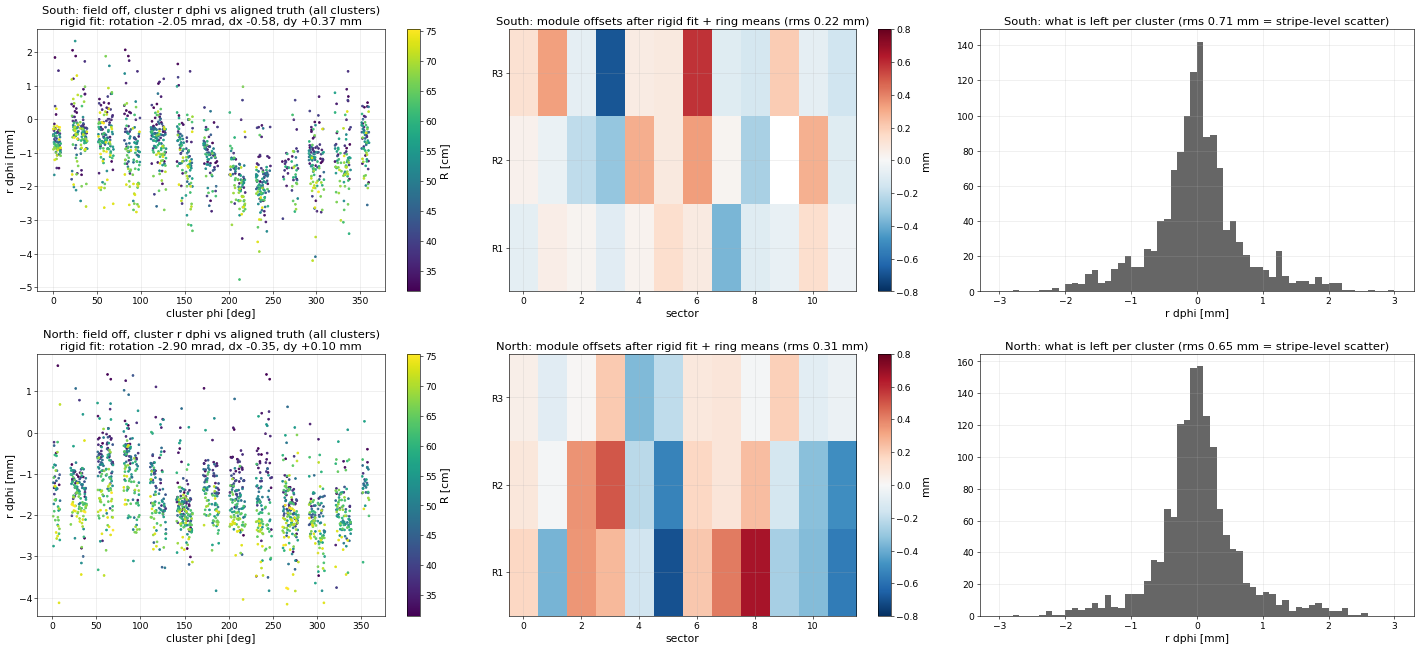

In [3]:
show(rv.fig_fieldoff())

# 2. Space charge: low vs high luminosity in the same fill, and static
Inside a fill the run-to-run change of the module medians is one sector pattern proportional to the GEM current (the same per µA in independent
pairs, correlation 0.75–0.99): per-module space charge the maps miss. That pattern, fitted per module (v13), halves the cross-fill pattern, but
the module weights did not carry to tracks equally in both sides (see the findings notebook).

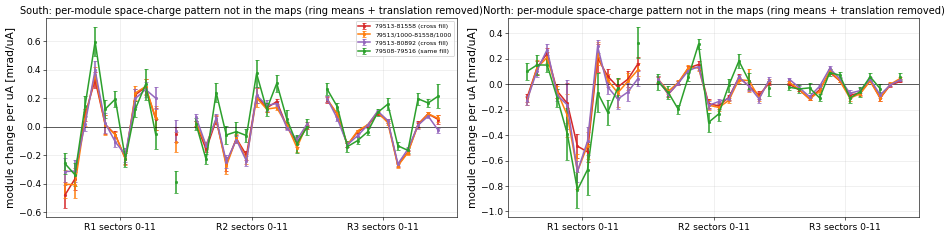

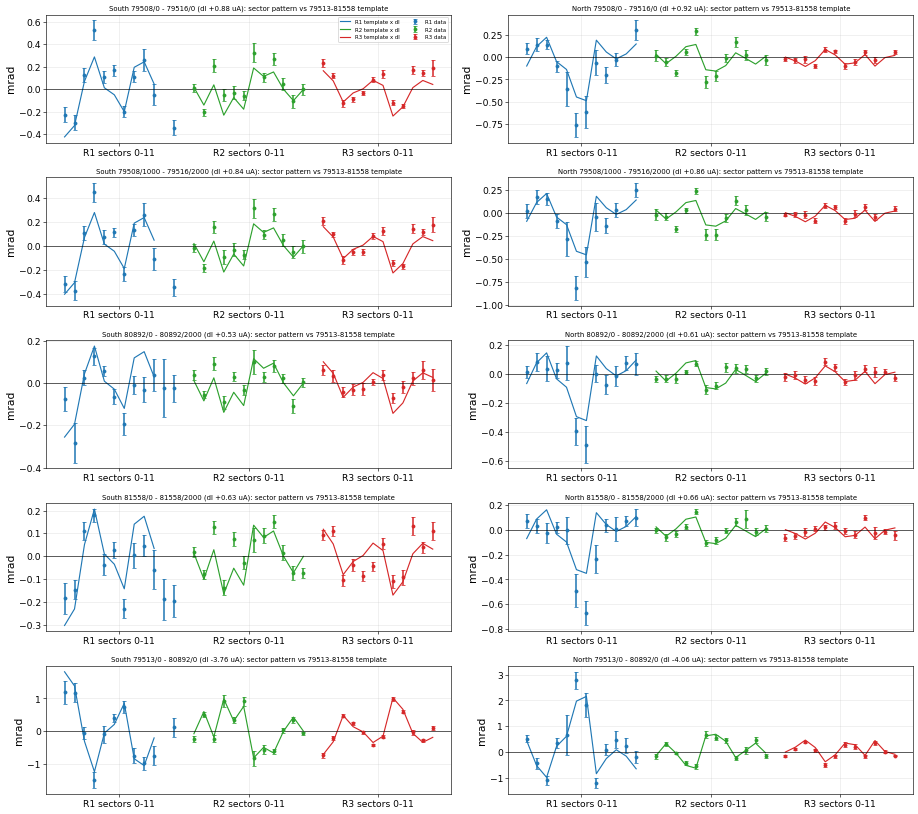

In [4]:
show(cm.fig_pattern_per_uA(), cm.fig_pattern_prediction())

**Static.** One fit of all 14 beam blocks (static + slope × I + per-fill φ-symmetric terms) describes the blocks to 0.09 mrad; the static
sector pattern at I = 0 is that of the no-beam field-on runs. It exists in no static model (CDB or PHGarfield: IFC/OFC/frames/magnet are all
sector-symmetric). The CDB-left CM residual of 79513 is mostly this static: slopes ≤ 0.1 mm/µA, static parts up to 0.5–0.9 mm per sector
(in North the same in all three rings, i.e. a whole-sector offset).

track sagitta per sector (cells, 3-pad COG (2 rows)), 14 beam blocks x 12 sectors: rms / worst [um] / within +-200 um
  South as measured                               : rms  1208, worst  3384, within  11%
  South per-cell static removed (A + fill terms)  : rms   889, worst  2748, within  29%
  South static + linear SC removed (full model)   : rms   135, worst  1213, within  93%
  South model fit residual 0.145 mrad per cell
  North as measured                               : rms   831, worst  2353, within  22%
  North per-cell static removed (A + fill terms)  : rms   683, worst  2209, within  31%
  North static + linear SC removed (full model)   : rms    90, worst   463, within  98%
  North model fit residual 0.165 mrad per cell
  South static A(I=0) sector sagitta: rms 732 um | 75073: rms 890 um, corr with A +0.90 | 83319: rms 1521 um, corr with A -0.17
  North static A(I=0) sector sagitta: rms 527 um | 75073: rms 804 um, corr with A +0.81 | 83319: rms 1276 um, corr with A +0.84


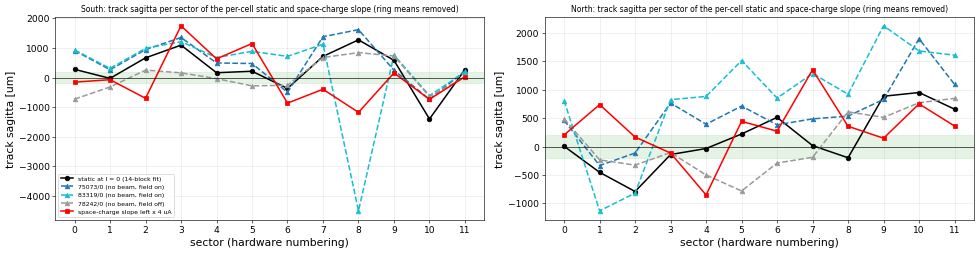

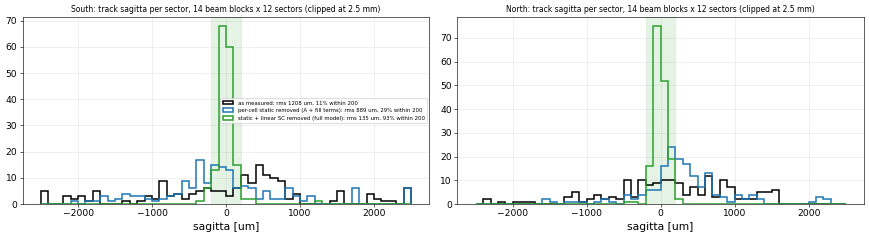

In [5]:
show(cm.fig_static_sectors(), cm.fig_sector_sag_hist())

# 3. CM → tracks
A track at (φ0, q, pT, η) has its clusters at φ_i = φ0 − q·asin(r_i/2R); the CM distortion is scaled with the drift length. The model predicts
how tracks change for every configuration difference (pointing, η dependence, curvature). **Caveat:** all configurations we scanned (keff, maps,
gains) move the *same* pattern up or down, so the −0.98 correlation validates the size of that one move, not the ability to set the absolute state.

pointing change X - final: phi-averaged mean (predicted / measured, mm) and the phi shape (correlation, predicted and
measured rms after removing the mean per pT bin); curvature: predicted d(q/pT) and measured change of N+/N-
South
  static             mean +12.288 / -3.890 | shape corr -0.73, rms 0.531 / 3.690 | dq/pT -153.11e-3, dN+/N- +4.729
  gain               mean -0.184 / -0.107 | shape corr -0.64, rms 0.735 / 0.972 | dq/pT  +4.88e-3, dN+/N- -0.022
  gain_half          mean -0.092 / -0.013 | shape corr -0.52, rms 0.368 / 0.724 | dq/pT  +2.44e-3, dN+/N- -0.021
  gain_free          mean +1.120 / -1.467 | shape corr -0.64, rms 0.714 / 1.098 | dq/pT -10.56e-3, dN+/N- +0.150
  shape_a16_k094     mean +0.964 / -1.005 | shape corr -0.25, rms 0.043 / 0.732 | dq/pT -14.69e-3, dN+/N- +0.141
  shape_a16_k100     mean +0.237 / -0.294 | shape corr -0.12, rms 0.014 / 0.490 | dq/pT  -5.81e-3, dN+/N- +0.044
  shape_a16_k106     mean -0.491 / +0.507 | shape corr +0.27, rms 0.021 / 0.538 | dq/pT 

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmtrk.py:279: RuntimeWarning: Mean of empty slice
  Ms = Mm - np.nanmean(Mm, axis=1, keepdims=True)
/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


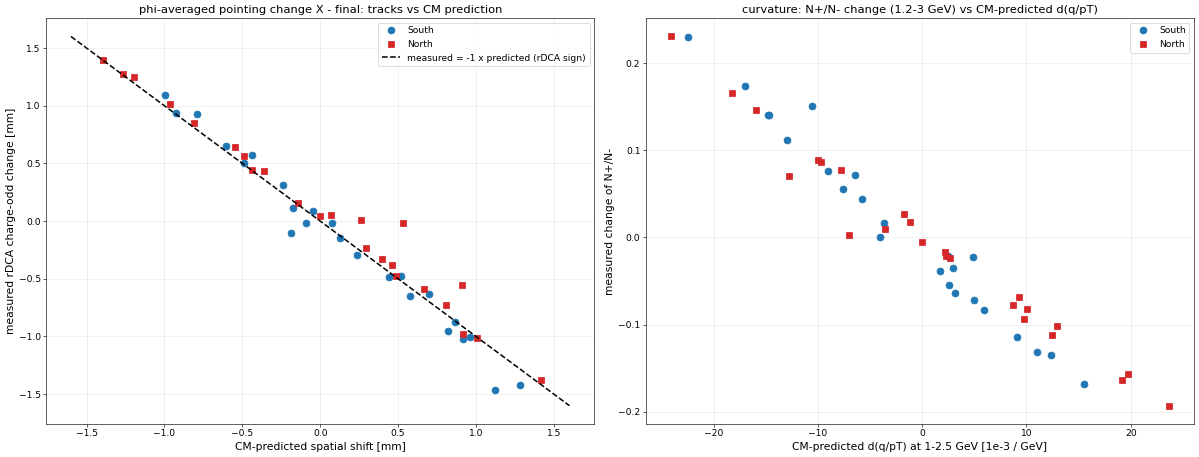

In [6]:
rows_c = ct.compare_diffs()
T = ct.split_table(rows_c)
show(ct.fig_mean_scatter(T))

# 4. Tracks: CDB, final (CM-tuned PHGarfield), α 1.25
* **Momentum** is read from N+/N− of tracks above 1.2 GeV (a charge-dependent curvature bias changes it; expected in p+p ≈ 1.05).
  CDB: 1.06 / 1.21 (S/N); `final`: 0.93 / 0.95 (circle fit), 0.97 / 1.00 (ACTS fit with the field map): **the CM-tuned configuration over-corrects
  the momentum.** `a125_p0` (α 1.25, keff ×1.14 S / ×1.07 N): pointing ≈ 0 and N+/N− 1.00 / 1.07 with the same residuals as `final`.
* **N+/N− falls with |η|** at high pT in all configurations (low pT stays flat): a charge-dependent curvature bias growing with z.
* **Per-sector structure** in φ is present in all configurations, and the same in two independent halves of the data.

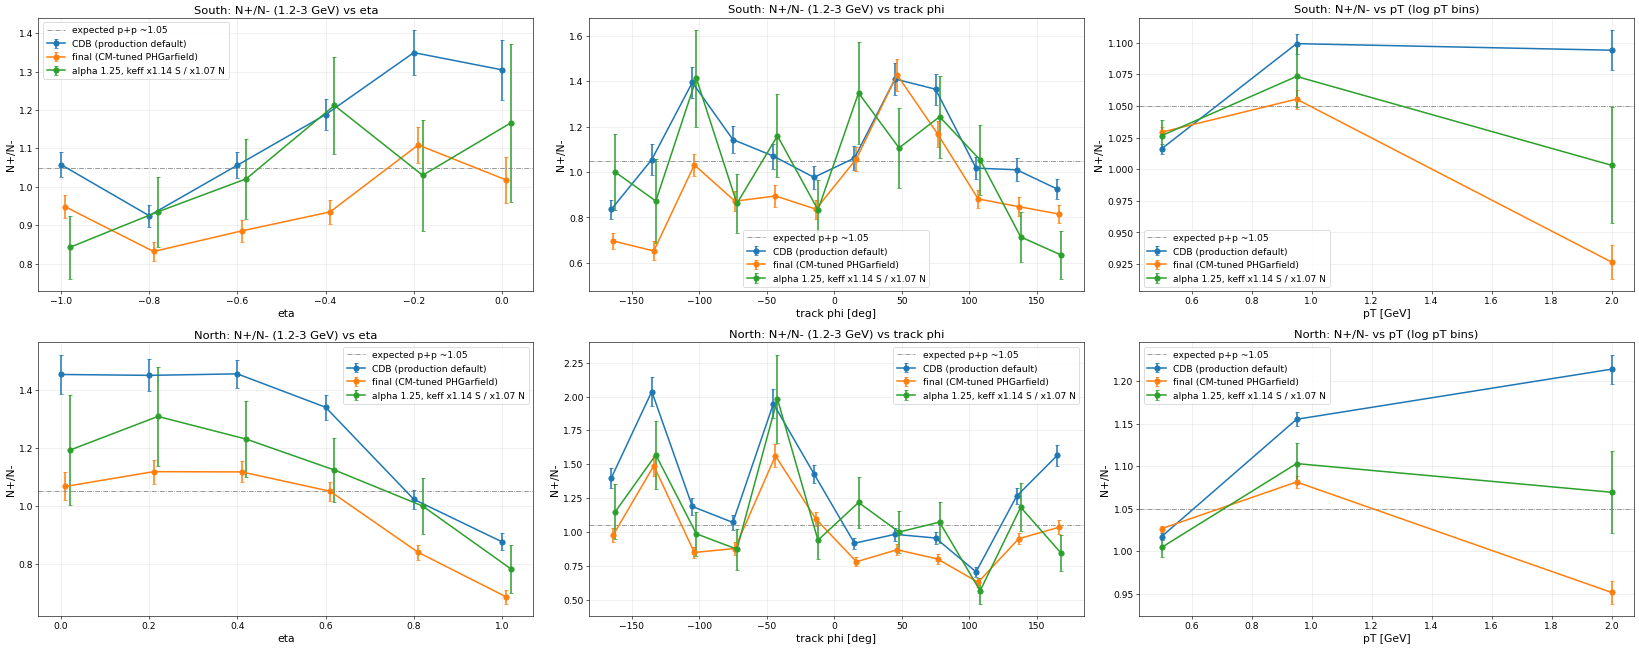

In [7]:
show(rv.fig_tracks_eta_phi())

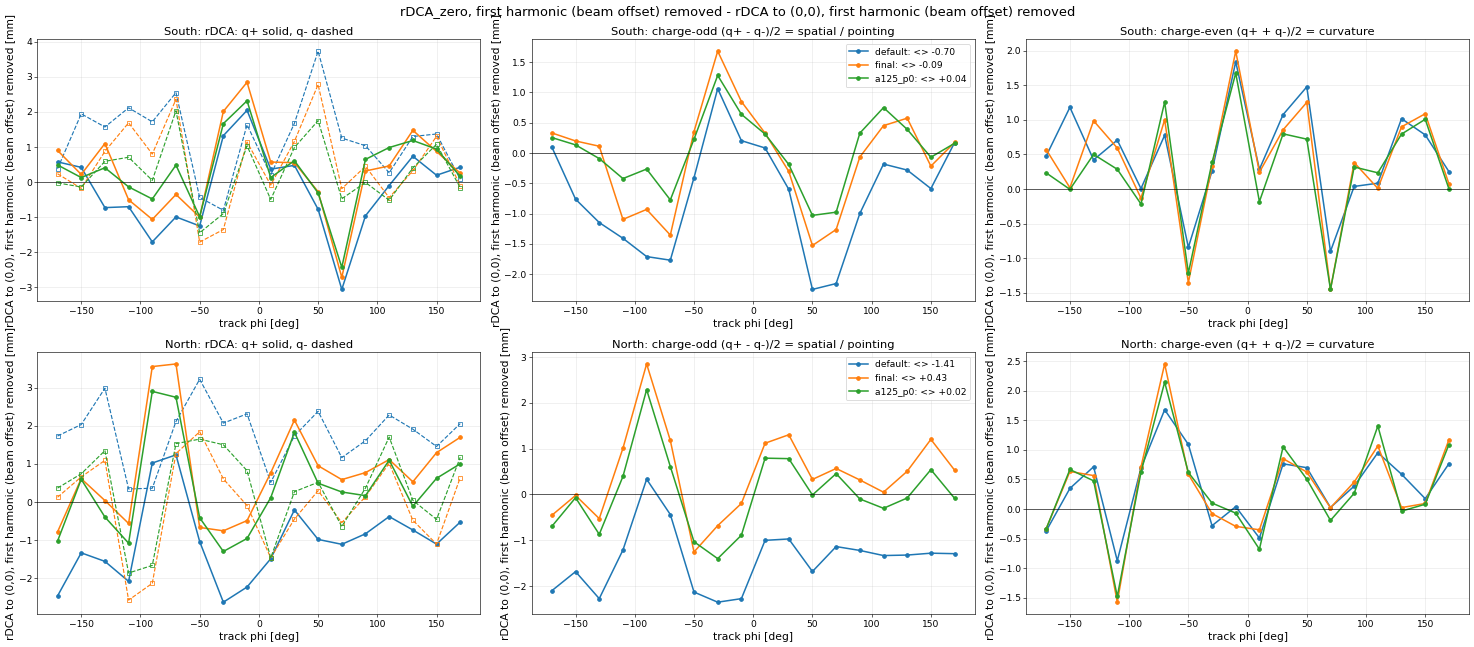

In [8]:
show(ta.fig_dca_big(['default', 'final', 'a125_p0'], 'rDCA_zero, first harmonic (beam offset) removed', 'nosine'))

**What the rDCA panels can and cannot show.** With `rDCA_zero = q·d0`, the mean of the two charges is d0 (pointing + the beam offset in the
TPC frame) and the half difference is curvature-type. The 2–4 mm first harmonic of d0 is the beam offset: the CM cannot see it and it is the
largest signal in every rDCA plot, so those plots mostly show what we cannot fix. Table:

In [9]:
rv.sn_table()

rDCA_zero (to (0,0)), core mean per 20 deg phi bin, mm:
config     side     tracks  odd 1st-harm.  odd after sine rms  even 1st-harm.  even rms
default    South    495184          -2.65                0.88           -0.04      0.69
default    North    523766          -1.91                0.67           -0.33      0.71
final      South    499364          -3.74                0.83            0.07      0.84
final      North    528305          -1.66                0.92           -0.34      0.86
a125_p0    South     49391          -3.37                0.58           -0.06      0.75
a125_p0    North     52369          -1.83                0.84           -0.38      0.84
odd = (q+ - q-)/2 = d0 common to both charges (pointing + beam offset); even = (q+ + q-)/2 = curvature-type.
First harmonic: odd 1.7-3.7 mm (beam offset in the TPC frame, invisible to the CM) vs even 0.04-0.4 mm. After removing the sine the sector
structure is comparable in both (rms 0.6-0.9 mm); the even part is dominated by 

# 5. K0s (79513 PR_full, StudyK0sDoublePeakQA cuts) — the independent constraint
* **Width vs φ** is nearly flat (6.7–7.1 MeV for φ > 0, up to 8.1 MeV at −135°). A sagitta bias broadens the peak without shifting it (toy: 240 µm
  → 7.2 MeV, 540 µm → 9.8 MeV from 6.5), so the width bounds the sagitta structure per sector.
* The CDB-left CM predicts a South track sagitta of +700…+1100 µm around φ = −165…−135° and +560…+715 µm at φ > 100°. The width **is** largest at
  −135° (+1.5 MeV), but by about a factor 5–10 less than 1 mm would give: **the CM-predicted South sagitta is overstated**, or only part of it
  reaches the tracks. Its pointing-like part did match the tracks; its R² part should be constrained with K0s.
* **Mass vs decay radius at fixed pT:** the low-pT mass deficit (≈ 8 MeV) exists only for K0s decaying inside the silicon (r < 11 cm): energy loss in
  the beampipe and silicon on average per side, not a TPC momentum scale. K0s mass is not a distortion observable; K0s width and the daughter
  balance (mass vs pT asymmetry) are.

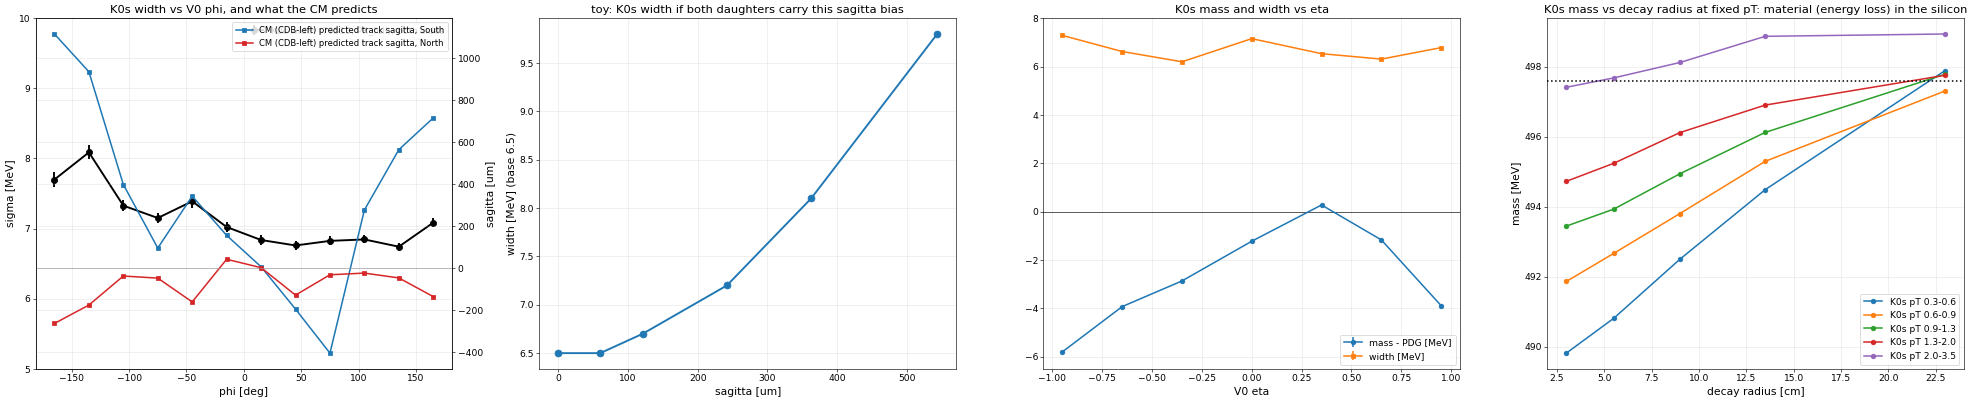

In [10]:
show(rv.fig_k0s())

K0s from TpcHadronReco on the same events (10 segments, loose selection), CDB vs `final`: the peak is only ≈ 500–1000 K0s per side, so this
is a visual check only; the two look the same within the errors.

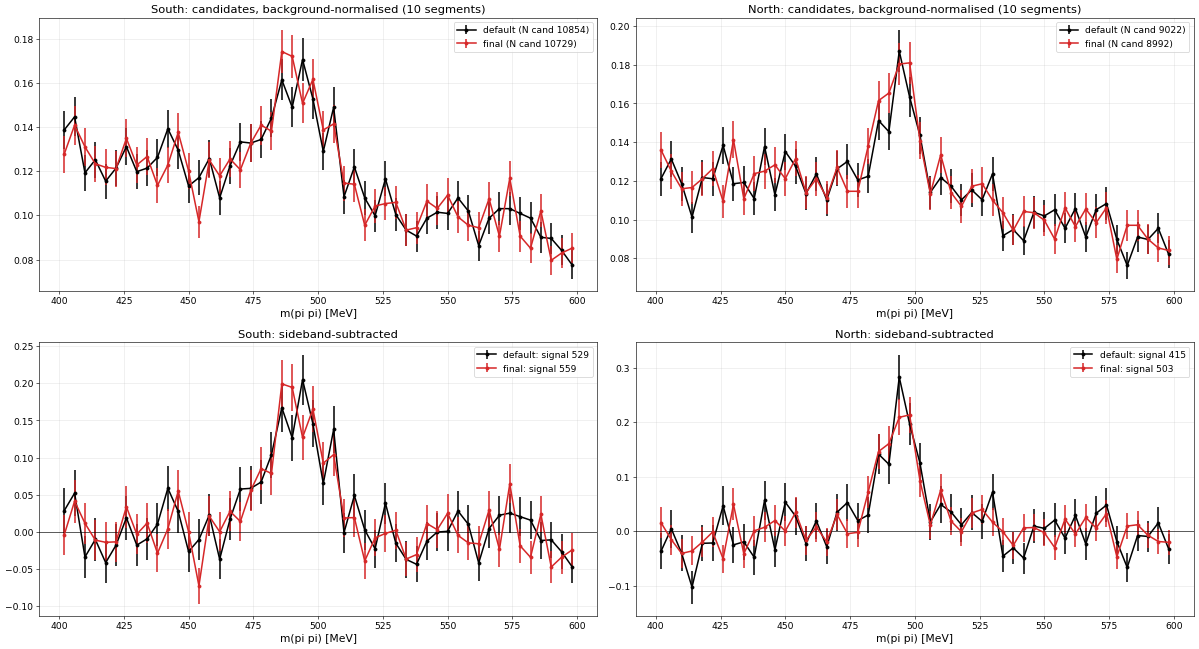

In [11]:
show(rv.fig_k0s_cdb_vs_final())

# 6. CM-based maps on top of CDB in TpcHadronReco
Map = what the CDB-corrected CM still shows (cluster − aligned truth) as r·Δφ, with a z law; applied as corrected = measured − map to the clusters
before the ACTS fit (10 segments × 1000 events, same DSTs for every map).

| map (added to CDB) | South | North |
|---|---|---|
| full CM residual × drift | pointing rms 0.88 → 0.64, φ structure of N+/N− −45 % | pointing rms 0.78 → 0.86, φ structure unchanged |
| φ average × B_r law | η drop of N+/N− −0.33 → −0.16 | −0.40 → −0.18 |
| φ structure × drift | pointing rms 0.67, φ structure −35 % | not seen by tracks (correlation −0.05) |
| `best1` = φ average × B_r + South φ structure × drift | **best on every South metric; scale ×1.5 is worse** | η drop −0.18, φ structure slightly worse |
| North per-sector static (z-independent / × drift) on top | – | pointing rms 1.07 → 1.00 per sector, largest sector 3.2 → 1.7 mm; N+/N− per sector unchanged |
| field-off terms as extra pad or drift correction | clearly worse | clearly worse |

South gets better with the CM on top of CDB; North does not, and the North CM static shows up in tracks only in pointing.

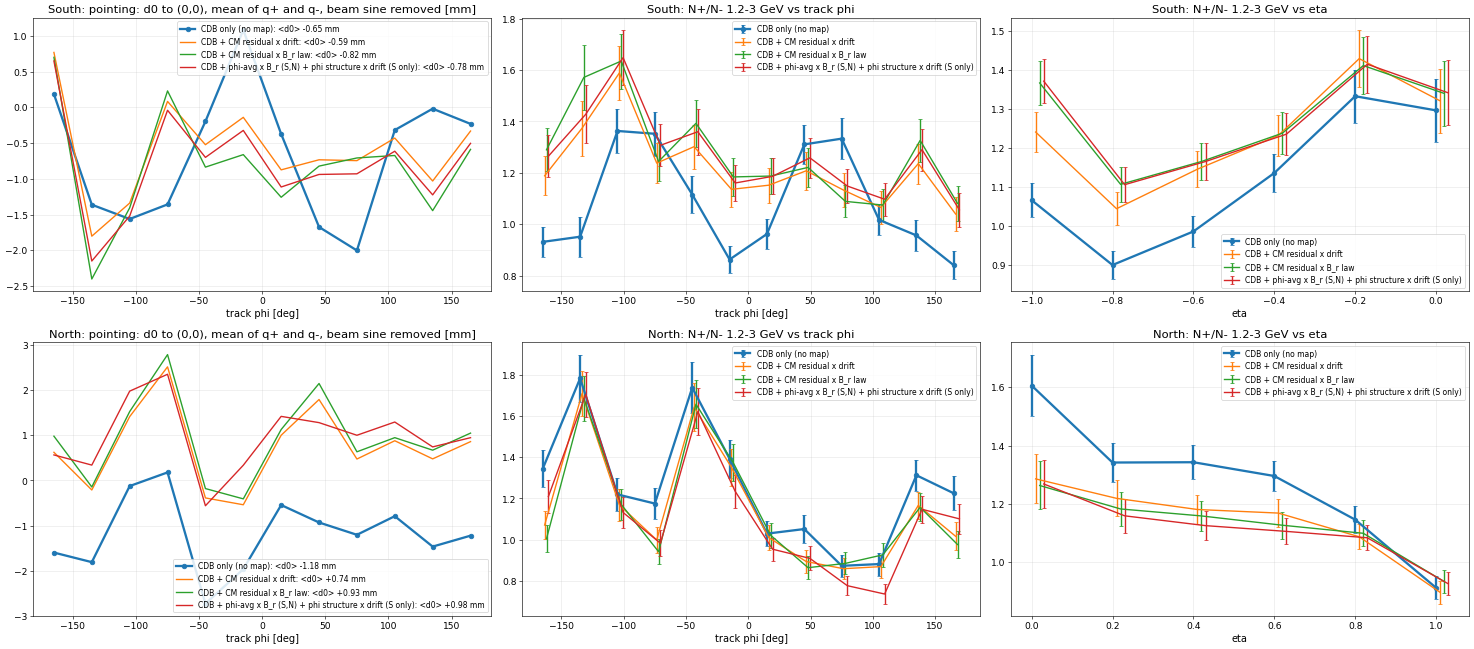

In [12]:
show(rv.fig_v0maps())

# 7. Audit: where we could fool ourselves

**Errors found in our own analysis (all fixed):**
1. **File-pattern contamination.** The TpcHadronReco histogram for `final` was built from `v0_final_*.root`, which also matched `v0_final_k090_*`. It
   mixed `final` with keff ×0.90 (twice the candidates; N+/N− 1.04 / 1.07 instead of the correct 0.97 / 1.00). The claim "the field map in the fit makes
   final's momentum closer to right" was an artifact. Also: the `lin` histogram contained `lin_half`; several histogram jobs ran before the
   reconstruction jobs had finished and wrote empty files. All rebuilt from exact file lists; the macro now matches only `_<digits>`.
2. The field-off "pad" test `zfpad` had the sign of the field-off term inverted (redone as `zfpad2`, `modpad`).
3. The table columns "res odd / even rms" were the rms over R of the mean residual (a bias), not a residual width.
4. The module's `rDCA` to its own TPC vertex is built from the same tracks and is self-biased; dropped, together with the gain fit that used it.
5. Charge-odd / charge-even labels were swapped for a while; `rDCA_zero = q·d0`, so odd = pointing, even = curvature.
6. K0s mass vs η was first attributed to something other than material; decay radius and pT are correlated, but at fixed pT the low-pT mass
   deficit exists only inside the silicon.

**Where we can still fool ourselves:**
* **The CM reference is not the track reference.** K0s daughter balance agreed with CDB's laser sagitta (−190 / −210 µm against the truth); driving the CM to
  zero over-corrects the momentum (N+/N− 0.93–1.00 vs ≈ 1.05 expected; CDB 1.06 South). A better CM agreement made tracks worse, which is the pattern of
  all earlier attempts.
* **The CM-predicted per-sector sagitta is too large** by ≥ 5× compared with the K0s width (above): do not apply the R² part of the CM φ structure
  without a K0s constraint.
* **Observables.** N+/N− depends on the selection (low-pT value 1.03 in one, 1.24 in the TpcHadronReco selection) and on acceptance holes (South q−
  around −140°); always use differences against a baseline in the same selection, and the high/low-pT ratio. K0s mass is dominated by energy loss.
* **Pointing** is dominated by the beam offset (2–4 mm, invisible to the CM); removing its first harmonic also removes any real first-harmonic
  distortion. The North sector at 270° sits +3.2 mm off in **every** configuration, CDB included: a candidate for the tracking geometry (all TPC
  alignment entries are zero), not the CM.
* **Statistics and comparability.** 10 segments (10k events): per-sector N+/N− stat ±0.07–0.11, φ-binned ±0.06; `default` and `final` have 100 segments
  while the other configurations have 10 — compare only within the same event set. Gains of 15–45 % in the φ structure depend on the metric.
* **Independence.** Two halves of the 10 segments reproduce the CDB structure (pointing correlation 1.00, N+/N− 0.86 South / 0.79 North) and the map
  responses (South 0.96–0.98), but they use the same DSTs and the same clusters, so this shows the effects are not noise, not that the maps are right.
* **One run, one field-off reference, full drift only.** The z law (B_r-like preferred) is inferred from N+/N− vs η alone.

# 8. Plan
1. **Fix the acceptance criteria before the next run** (full 79513, TpcHadronReco, CDB vs CDB + `best1` vs `a125_p0`): K0s width vs φ and η for
   decay radius > 15 cm, daughter balance vs φ, N+/N− high/low-pT ratio vs φ and η, pointing structure after the beam sine. A configuration counts
   as better only if none of them is worse.
2. **CM only where tracks confirm it:** φ average with the B_r z law (both sides) and the South pointing-like structure; the R² part of the
   per-sector structure only after a K0s width / balance constraint.
3. **Make the truth more realistic** (stripe-level scatter 0.7 mm, the per-module offsets, the 200 µm sagitta reference of the truth) so the CM
   reference agrees with K0s balance.
4. **North:** the static per-sector CM pattern appears in pointing but not in momentum; check the tracking geometry (zero TPC alignment) and the 270° sector.
5. **Keep PHGarfield changes physical:** α 1.25 with keff ×1.14 / ×1.07 is a candidate for the PHGarfield-only route; the CM-on-top route is
   cheaper (a second TpcHadronReco pass).